# Agent 02: RL-based agent vs rule-based agent in an e-commerce market

Two shops sell the same product. At every step each one decides whether to give a **20% discount**. A discount brings more buyers but less profit per sale, and it steals buyers from the other shop.

We put two kinds of decision maker in this market:

* **Agent A, reinforcement learning (Q-learning):** starts knowing nothing and learns from the profit it earns.
* **Agent B, rule-based:** follows three hand-written *if-then* rules and never changes.

This notebook runs every experiment of the assignment step by step. All the code lives in `code/agent02_experiment.py` (the file the assignment asks for); the notebook imports it, explains each step and shows the results. Running the whole notebook takes about 25 minutes and rewrites `results/` (the results are deterministic, so they are identical to the ones in the report).

In [1]:
import sys, csv
from pathlib import Path
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import agent02_experiment as m

config = m.Config()
for d in (m.OUT, m.FIG, m.TAB):
    d.mkdir(parents=True, exist_ok=True)
(m.OUT / "q_tables.txt").unlink(missing_ok=True)

def show_csv(name, cols=None, digits=3):
    with open(m.OUT / name, encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            return f"{float(v):.{digits}f}" if "." in v else v
        except ValueError:
            return v
    widths = [max(len(c), *(len(fmt(r[c])) for r in rows)) for c in cols]
    print("  ".join(c.ljust(w) for c, w in zip(cols, widths)))
    for r in rows:
        print("  ".join(fmt(r[c]).ljust(w) for c, w in zip(cols, widths)))

print(config)
print("seeds for repeated runs:", m.SEEDS)

Config(episodes=5000, steps_per_episode=20, alpha=0.1, gamma=0.9, epsilon_start=0.2, epsilon_min=0.02, epsilon_decay=0.995, price=10.0, unit_cost=5.0, discount_rate=0.2, low_demand_customers=10, high_demand_customers=20, seed=42, evaluation_episodes=500, window=100)
seeds for repeated runs: [11, 22, 33, 44, 55, 66, 77, 88, 99, 110]


## 1. The environment

Each agent observes a **state** $s = (d, c)$:

* $d$ = demand: 0 low (10 potential customers), 1 high (20 customers);
* $c$ = what the **competitor did at the previous step** (0 no discount, 1 discount).

Both agents choose an **action** (0 = no discount, 1 = discount) *at the same time*. Each customer buys with probability

$$p_i = \mathrm{clip}(0.30 + 0.25\,d + 0.15\,a_i - 0.10\,a_{-i},\ 0.05,\ 0.95)$$

so my discount helps me (+0.15) and the rival's discount hurts me (-0.10). Sales are $\mathrm{Binomial}(N, p_i)$ and the **reward** is profit: 5 per sale at full price (10 - 5), 3 per sale with a discount (8 - 5). Demand for the next step is a coin flip.

Let us play one step by hand.

In [2]:
env = m.ECommerceEnvironment(config, seed=0)
states = env.reset()
print("states after reset (agent 0, agent 1):", states)
next_states, rewards, info = env.step([1, 0])   # agent 0 discounts, agent 1 does not
print("conversion probabilities:", info["conversion"])
print("customers:", info["customers"], " sales:", info["sales"])
print("rewards (profit):", rewards)
print("next states:", next_states, " <- each agent now sees the other's last action")

states after reset (agent 0, agent 1): [(1, 0), (1, 0)]
conversion probabilities: [0.7000000000000001, 0.45000000000000007]
customers: 20  sales: [15, 5]
rewards (profit): [45.0, 25.0]
next states: [(1, 0), (1, 1)]  <- each agent now sees the other's last action


### What should a smart shop do? Expected profit per step

Before learning anything, we can compute the *expected* profit $N \cdot p \cdot \text{margin}$ for each case.

In [3]:
m.experiment_model(config)


== Expected one-step profit (analysis of the model) ==
{'demand': 0, 'competitor_current_action': 0, 'E_profit_action_0': np.float64(15.0), 'E_profit_action_1': np.float64(13.5), 'myopic_best_action': 0}
{'demand': 0, 'competitor_current_action': 1, 'E_profit_action_0': np.float64(9.999999999999998), 'E_profit_action_1': np.float64(10.5), 'myopic_best_action': 1}
{'demand': 1, 'competitor_current_action': 0, 'E_profit_action_0': np.float64(55.0), 'E_profit_action_1': np.float64(42.00000000000001), 'myopic_best_action': 0}
{'demand': 1, 'competitor_current_action': 1, 'E_profit_action_0': np.float64(45.00000000000001), 'E_profit_action_1': np.float64(36.00000000000001), 'myopic_best_action': 0}


Not discounting wins in 3 of 4 cases. The only case where a discount pays (low demand while the rival discounts) never happens against the rule-based rival, because the rule never discounts in low demand. Worse, a discount has a **delayed cost**: the rule copies our discount at the next high-demand step, which cuts our next profit from 55 to 45.

So the best policy against the rule is **never discount**, worth $0.5 \cdot 15 + 0.5 \cdot 55 = 35$ per step. This is the benchmark for everything below.

## 2. The two agents

**Rule-based agent:** low demand → no discount; high demand and the rival discounted last step → discount; otherwise no discount. It never learns.

**Q-learning agent:** keeps a table $Q(s, a)$ of 4 states × 2 actions = 8 numbers ("how much total future profit do I expect if I take action $a$ in state $s$?"). It picks the action with the larger $Q$, except that with probability $\varepsilon$ it tries a random action (exploration). After each step:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

**Worked example (Question 3):** $Q(s,a)=4$, $\alpha=0.1$, $r=6$, $\gamma=0.9$, $\max_{a'}Q(s',a')=5$.

In [4]:
agent = m.QLearningAgent(alpha=0.1, gamma=0.9, epsilon=0.0, seed=0)
agent.q[0, 0, 1] = 4.0            # Q(s, a) = 4 for s = (0, 0), a = 1
agent.q[1, 0, :] = [5.0, 1.0]     # max_a' Q(s', a') = 5 for s' = (1, 0)
target = 6 + 0.9 * 5
print(f"target   = 6 + 0.9 * 5 = {target}")
print(f"TD error = {target} - 4 = {target - 4}")
agent.learn((0, 0), 1, 6.0, (1, 0))
print(f"new Q    = 4 + 0.1 * {target - 4} = {agent.q[0, 0, 1]:.2f}")

target   = 6 + 0.9 * 5 = 10.5
TD error = 10.5 - 4 = 6.5
new Q    = 4 + 0.1 * 6.5 = 4.65


The outcome (10.5) was better than expected (4), so the value goes up, but only by 10% of the gap: one lucky step is not trusted completely.

## 3. Experiments A and B: the baseline (seed 42)

Train the RL agent for 5,000 episodes × 20 steps against the rule-based agent, then **evaluate separately**: Q-table frozen, $\varepsilon = 0$, a new environment seed.

To compare the two *policies* fairly, the rule-based agent is also evaluated in the **same seat, against the same opponent, with the same seed**. Both runs then see exactly the same demand sequence.

In [5]:
baseline_agent = m.experiment_a_b(config)


== Experiment A/B: baseline (seed 42) ==


RL vs Rule    seat 0 RL         total=351275 mean/step=35.127 discounts=0 no-discounts=10000
RL vs Rule    seat 1 Rule-based total=349685 mean/step=34.968 discounts=0 no-discounts=10000
Rule vs Rule  seat 0 Rule-based total=351275 mean/step=35.127 discounts=0 no-discounts=10000
Rule vs Rule  seat 1 Rule-based total=349685 mean/step=34.968 discounts=0 no-discounts=10000
Baseline Q-table
Q[demand, competitor_previous_action, action]; action 0 = no discount, 1 = discount
  state=(0, 0) | Q0= 228.3024 | Q1= 178.8494 | visits=(33659, 12490) | greedy=NO DISCOUNT
  state=(0, 1) | Q0= 177.9920 | Q1= 207.2051 | visits=(2501, 1522) | greedy=DISCOUNT
  state=(1, 0) | Q0= 246.8799 | Q1= 235.2338 | visits=(42848, 3103) | greedy=NO DISCOUNT
  state=(1, 1) | Q0= 211.4198 | Q1= 242.9629 | visits=(3468, 409) | greedy=DISCOUNT


{'rl_total_training_reward': 3345548.0, 'rule_total_training_reward': 3283930.0, 'rl_training_discount_actions': 17524, 'rule_training_discount_actions': 8323, 'total_training_s

In [6]:
show_csv("baseline_evaluation.csv",
         ["match", "agent", "seat", "total_reward", "mean_reward_per_step",
          "discount_actions", "no_discount_actions"])

match         agent       seat  total_reward  mean_reward_per_step  discount_actions  no_discount_actions
RL vs Rule    RL          0     351275.000    35.127                0                 10000              
RL vs Rule    Rule-based  1     349685.000    34.968                0                 10000              
Rule vs Rule  Rule-based  0     351275.000    35.127                0                 10000              
Rule vs Rule  Rule-based  1     349685.000    34.968                0                 10000              


In evaluation the RL agent never discounts and earns **exactly** the same total as the rule-based agent in the same seat: the two policies take identical actions on all 10,000 steps. In the Q-table, the states with $c=1$ say "discount", but they are rarely visited (the rival only discounts after we do) and never reached in greedy play.

### The learning curve (Experiment B)
Mean reward per step over windows of $K = 100$ episodes:

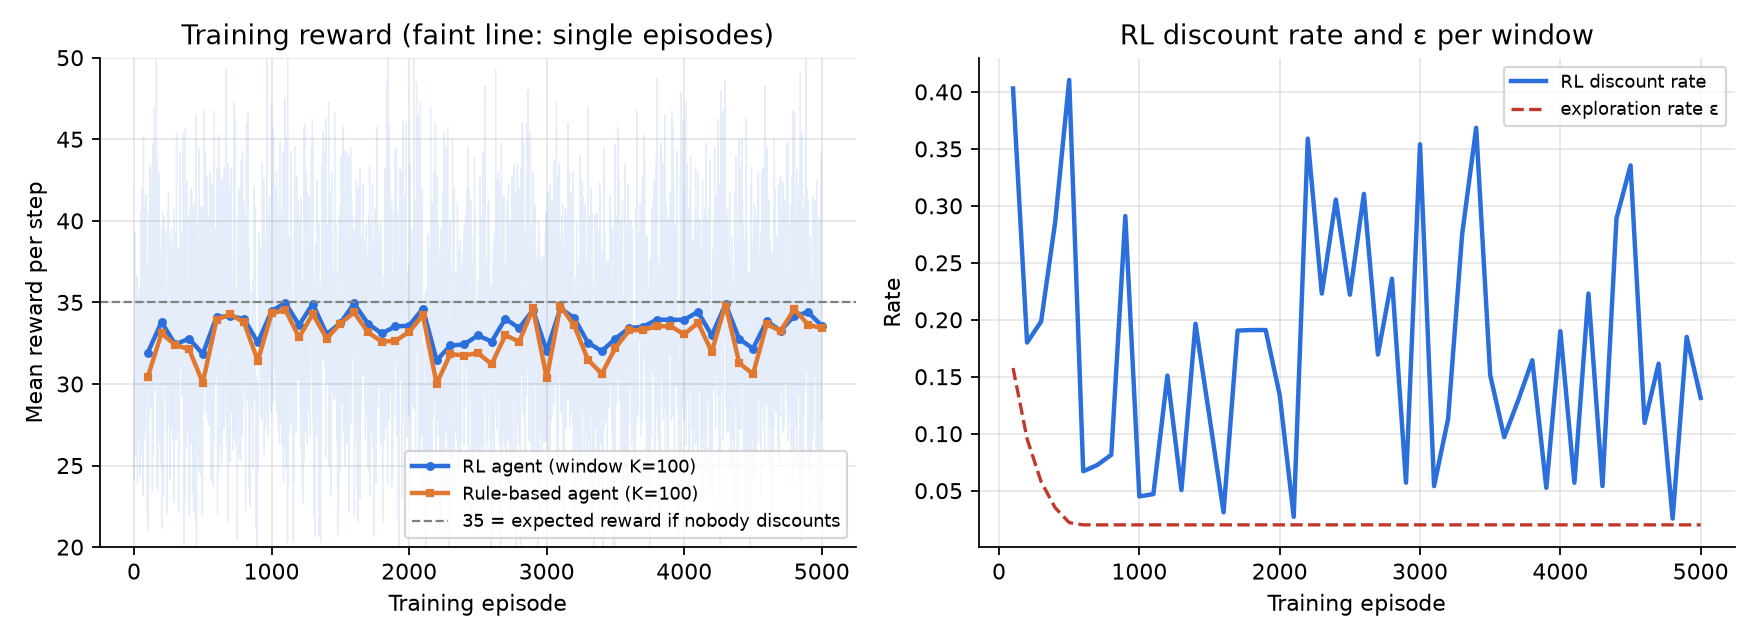

In [7]:
display(Image(filename=str(m.FIG / "baseline_training.png")))

Reward improves during the first ~500 episodes and then **fluctuates** between about 31 and 35. Exploration is already at its floor ($\varepsilon = 0.02$), yet the discount rate keeps jumping: the *greedy policy itself* keeps flipping (606 changes during training). A rising curve is not proof of convergence.

## 4. Experiment C: learning rate (10 seeds each)


== Experiment C: learning rate ==


{'configuration': 'alpha=0.01', 'n_seeds': 10, 'eval_mean_reward': 33.633889999999994, 'eval_std_across_seeds': 3.1930351929194623, 'train_mean_reward': 32.441345999999996, 'train_std_across_seeds': 2.2732112841343084, 'eval_discount_rate': 0.14977000000000001, 'seeds_with_never_discount_policy': 1, 'mean_policy_flips': 21.5}


{'configuration': 'alpha=0.10', 'n_seeds': 10, 'eval_mean_reward': 34.38976, 'eval_std_across_seeds': 1.2392711443963071, 'train_mean_reward': 33.608051, 'train_std_across_seeds': 0.1438560608115699, 'eval_discount_rate': 0.09098999999999999, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 584.1}


{'configuration': 'alpha=0.50', 'n_seeds': 10, 'eval_mean_reward': 32.04455, 'eval_std_across_seeds': 3.5090174209535574, 'train_mean_reward': 31.811658000000005, 'train_std_across_seeds': 0.08082152708282693, 'eval_discount_rate': 0.28662, 'seeds_with_never_discount_policy': 3, 'mean_policy_flips': 1769.9}


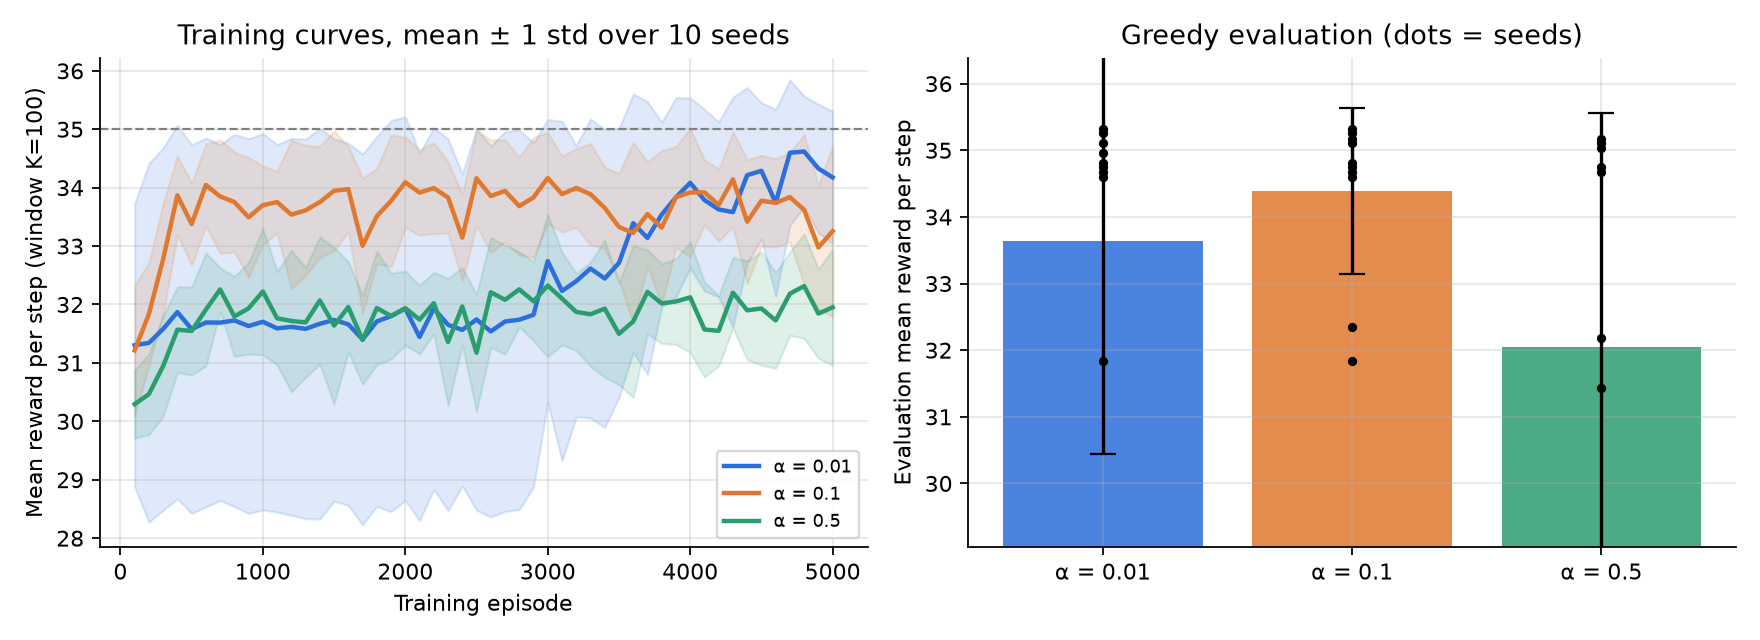

alpha  eval_mean_reward  eval_std_across_seeds  train_mean_reward  eval_discount_rate  seeds_with_never_discount_policy  mean_policy_flips
0.010  33.634            3.193                  32.441             0.150               1                                 21.500           
0.100  34.390            1.239                  33.608             0.091               4                                 584.100          
0.500  32.045            3.509                  31.812             0.287               3                                 1769.900         


In [8]:
lr_results = m.experiment_c(config)
display(Image(filename=str(m.FIG / "learning_rate_comparison.png")))
show_csv("learning_rate_comparison.csv",
         ["alpha", "eval_mean_reward", "eval_std_across_seeds", "train_mean_reward",
          "eval_discount_rate", "seeds_with_never_discount_policy", "mean_policy_flips"])

* $\alpha = 0.01$: very stable (few policy changes) but slow. Q-values are still rising from 0, so the action tried more often looks better simply because it has been updated more.
* $\alpha = 0.10$: best and most consistent.
* $\alpha = 0.50$: every new sample moves $Q$ a lot. With noisy sales the two actions get ranked almost at random, giving ~1,770 policy changes per run.

## 5. Experiment D: exploration (10 seeds each)


== Experiment D: exploration ==


{'configuration': 'Reference decay 0.20→0.02', 'n_seeds': 10, 'eval_mean_reward': 34.38976, 'eval_std_across_seeds': 1.2392711443963071, 'train_mean_reward': 33.608051, 'train_std_across_seeds': 0.1438560608115699, 'eval_discount_rate': 0.09098999999999999, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 584.1}


{'configuration': 'Fixed ε = 0.05', 'n_seeds': 10, 'eval_mean_reward': 34.12224, 'eval_std_across_seeds': 1.346495990174332, 'train_mean_reward': 32.909012, 'train_std_across_seeds': 0.20466913395906872, 'eval_discount_rate': 0.13189, 'seeds_with_never_discount_policy': 4, 'mean_policy_flips': 960.1}


{'configuration': 'Fixed ε = 0.30', 'n_seeds': 10, 'eval_mean_reward': 29.65407, 'eval_std_across_seeds': 3.2636494232513535, 'train_mean_reward': 30.887582, 'train_std_across_seeds': 0.1006333208347135, 'eval_discount_rate': 0.49468000000000006, 'seeds_with_never_discount_policy': 0, 'mean_policy_flips': 2428.8}


{'configuration': 'Greedy, ε = 0', 'n_seeds': 10, 'eval_mean_reward': 31.028790000000004, 'eval_std_across_seeds': 3.098531592885752, 'train_mean_reward': 31.094136000000002, 'train_std_across_seeds': 3.0689463126515886, 'eval_discount_rate': 0.43581000000000003, 'seeds_with_never_discount_policy': 3, 'mean_policy_flips': 0.0}


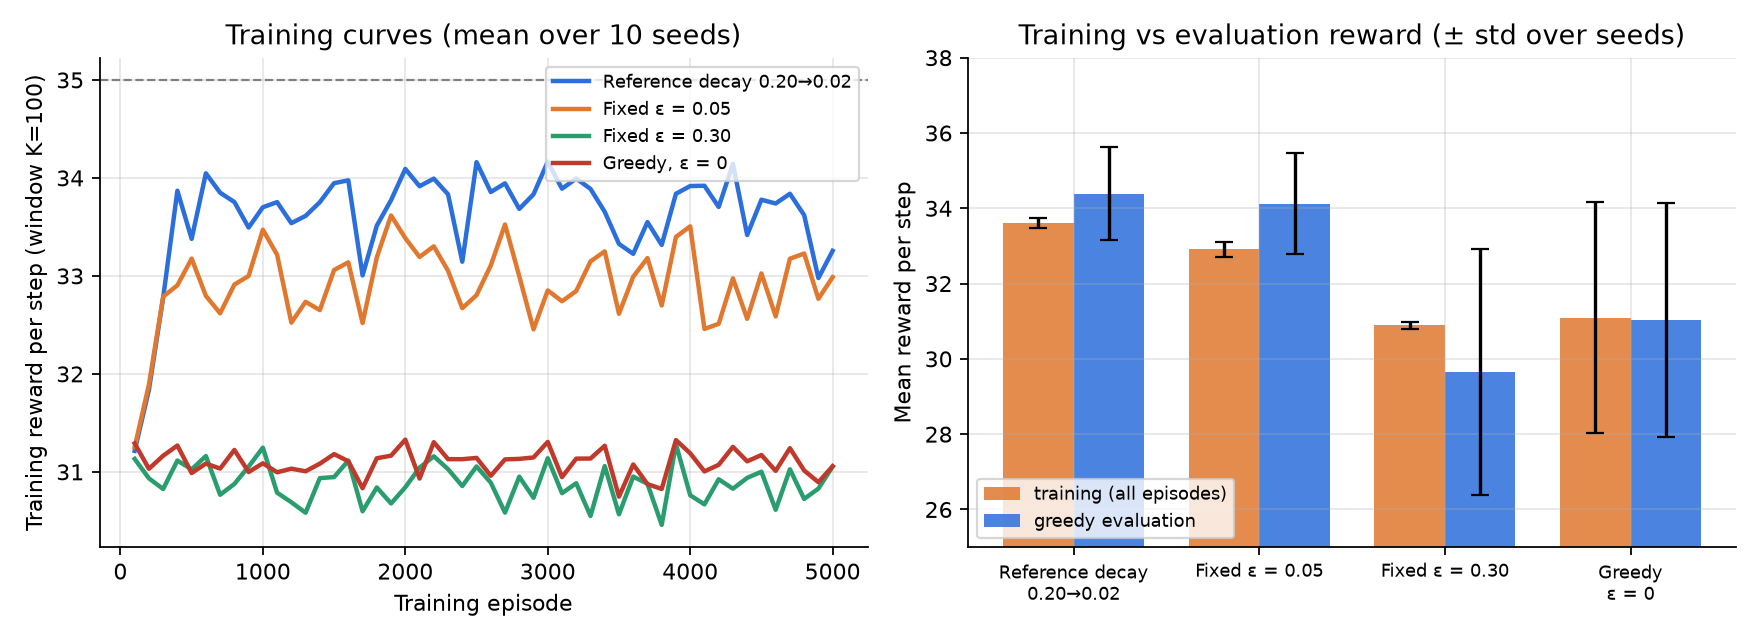

configuration              train_mean_reward  eval_mean_reward  eval_std_across_seeds  eval_discount_rate  seeds_with_never_discount_policy
Reference decay 0.20→0.02  33.608             34.390            1.239                  0.091               4                               
Fixed ε = 0.05             32.909             34.122            1.346                  0.132               4                               
Fixed ε = 0.30             30.888             29.654            3.264                  0.495               0                               
Greedy, ε = 0              31.094             31.029            3.099                  0.436               3                               


In [9]:
exp_results = m.experiment_d(config)
display(Image(filename=str(m.FIG / "exploration_comparison.png")))
show_csv("exploration_comparison.csv",
         ["configuration", "train_mean_reward", "eval_mean_reward", "eval_std_across_seeds",
          "eval_discount_rate", "seeds_with_never_discount_policy"])

* **Too much exploration** ($\varepsilon = 0.30$): pays for random discounts during training, and the learned values are so noisy that the final policy is also bad.
* **No exploration** ($\varepsilon = 0$): the first action tried in each state wins forever (0 policy changes). Whether that action was good is pure luck.
* **Decaying schedule:** explores early, exploits later, and gives the best training and evaluation reward.

## 6. Experiment E: fair comparison over 10 seeds


== Experiment E: fair comparison, 10 seeds ==


RL, baseline ($\alpha=0.10$, decaying $\varepsilon$)    mean=34.390 std=1.239 disc=0.091
RL, low learning rate ($\alpha=0.01$)                   mean=33.634 std=3.193 disc=0.150
RL, high learning rate ($\alpha=0.50$)                  mean=32.045 std=3.509 disc=0.287
RL, fixed $\varepsilon=0.05$                            mean=34.122 std=1.346 disc=0.132
RL, fixed $\varepsilon=0.30$                            mean=29.654 std=3.264 disc=0.495
RL, greedy $\varepsilon=0$                              mean=31.029 std=3.099 disc=0.436
Rule-based                                              mean=34.970 std=0.253 disc=0.000
Paired difference RL - Rule: mean=-0.580, std=1.231


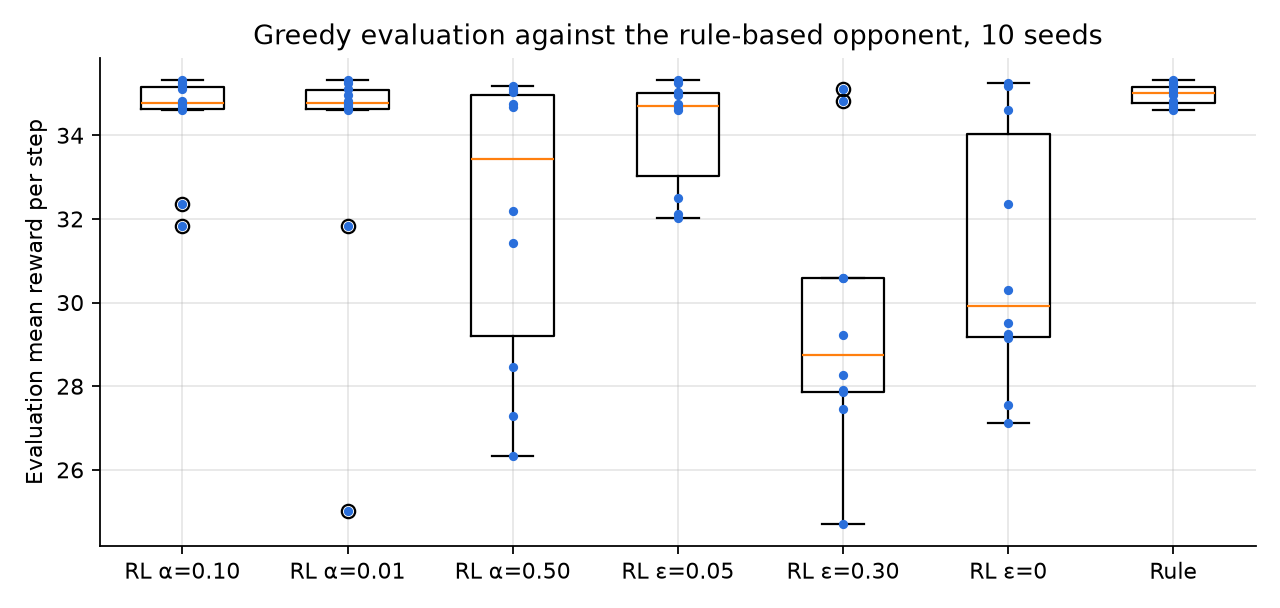

seed  difference
11    0.000     
22    0.000     
33    0.000     
44    0.000     
55    0.000     
66    -3.194    
77    -2.611    
88    0.000     
99    0.000     
110   0.000     


In [10]:
m.experiment_e(config, lr_results, exp_results)
display(Image(filename=str(m.FIG / "multi_seed_comparison.png")))
show_csv("paired_difference_rl_minus_rule.csv")

The rule-based agent is already playing the best response here, so RL can at most match it. It does so in 8 of 10 seeds (difference exactly 0) and is about 3 per step worse in the other 2. One seed alone (seed 42) would have hidden this.

## 7. Question 8: what if both agents learn?


== Question 8: two simultaneous learners ==


policy_flips_vs_rule                mean=584.100 std=24.538
policy_flips_vs_learning_rl         mean=589.400 std=25.369
rl_vs_rl_eval_reward_seat0          mean=33.625 std=1.858
rl_vs_rl_eval_reward_seat1          mean=33.616 std=2.005
rl_vs_rl_discount_rate_seat0        mean=0.171 std=0.236
rl_vs_rl_discount_rate_seat1        mean=0.212 std=0.299
late_flips_vs_rule                  mean=267.500 std=28.524
late_flips_vs_learning_rl           mean=272.600 std=28.691


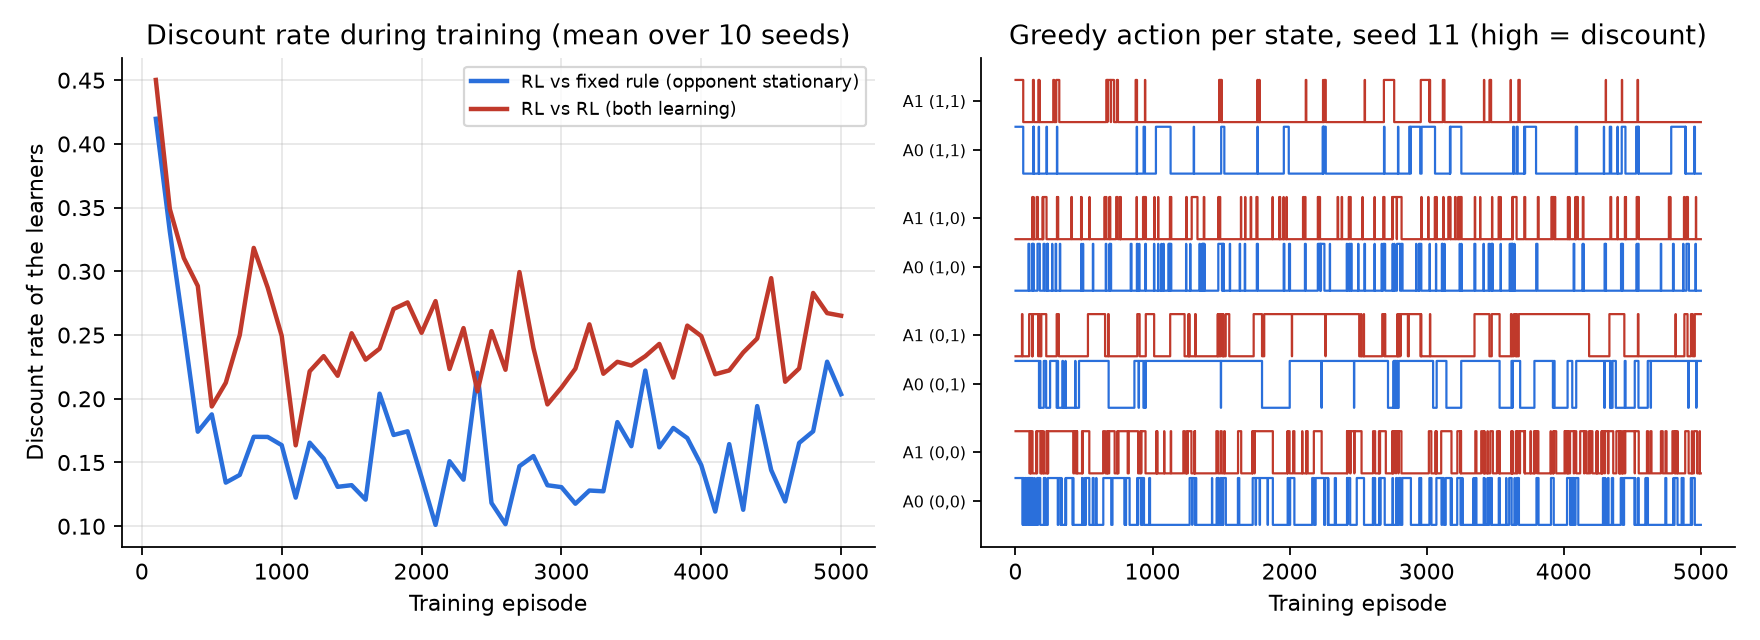

In [11]:
m.experiment_rl_vs_rl(config)
display(Image(filename=str(m.FIG / "rl_vs_rl.png")))

When the rival also learns, my environment changes while I learn (**non-stationarity**). The discount rate during training stays higher, and 4 of 10 pairs end with at least one agent still discounting. The policy-change count is similar in both settings: in this small problem the noise from a constant $\alpha$ already dominates.

## 8. Question 9: change the market, with an aggressive competitor
The rival now discounts **whenever demand is high**. Never discounting is still best (expected 30), but the rule-based agent's "match the rival" rule now fires on 25% of steps and costs 9 each time (expected 27.75).

In [12]:
m.experiment_modification(config)
show_csv("modification_aggressive.csv")


== Question 9: modified competitor (aggressive) ==


{'agent': 'RL retrained against the aggressive competitor', 'eval_mean': 28.75907, 'eval_std': 1.189018880375282, 'discount_rate': 0.32206}
{'agent': 'RL trained on the reference market (not retrained)', 'eval_mean': 29.314520000000005, 'eval_std': 0.9223910845671096, 'discount_rate': nan}
{'agent': 'Rule-based', 'eval_mean': 27.84178, 'eval_std': 0.15462921816756073, 'discount_rate': 0.23687999999999998}
Paired difference RL - Rule (aggressive market): mean=0.917, std=1.204
agent                                               eval_mean  eval_std  discount_rate
RL retrained against the aggressive competitor      28.759     1.189     0.322        
RL trained on the reference market (not retrained)  29.315     0.922     nan          
Rule-based                                          27.842     0.155     0.237        


The fixed rule drops to 27.84 (the calculation said 27.75). Both RL agents do better on average. A rule that fits one market can be the worst option in another.

## 9. Question 10: a more robust agent
Proposal: train against a **pool of opponents** (rule, aggressive, tit-for-tat, always discount, random) with a step size $\alpha = 1/N(s,a)$ that shrinks with experience. A second variant also puts the agent's **own previous action** in the state. Every agent is evaluated against every opponent, and the last row is the best possible expected reward computed from the model.

In [13]:
m.experiment_robustness(config)
show_csv("robustness_summary.csv", ["agent", "opponent", "mean", "std"])


== Question 10: robustness against a pool of opponents ==


Rule-based                             vs rule             34.984 ± 0.272
Rule-based                             vs aggressive       27.888 ± 0.137
Rule-based                             vs tit_for_tat      34.984 ± 0.272
Rule-based                             vs always_discount  23.230 ± 0.164
Rule-based                             vs random           28.613 ± 0.213
RL baseline (trained vs rule)          vs rule             34.418 ± 1.253
RL baseline (trained vs rule)          vs aggressive       29.321 ± 0.846
RL baseline (trained vs rule)          vs tit_for_tat      34.330 ± 1.459
RL baseline (trained vs rule)          vs always_discount  26.701 ± 1.741
RL baseline (trained vs rule)          vs random           30.609 ± 1.062
RL + opponent pool + α=1/N             vs rule             34.721 ± 0.767
RL + opponent pool + α=1/N             vs aggressive       29.826 ± 0.235
RL + opponent pool + α=1/N             vs tit_for_tat      34.702 ± 0.823
RL + opponent pool + α=1/N            

* The **rule-based agent** is perfect against the rule and tit-for-tat but loses 4.5 per step against an always-discounting rival.
* **Opponent pool + $\alpha = 1/N$** comes within 0.1-0.3 of the best response against every opponent, which makes it the most robust agent tested.
* Adding the own previous action **did not help** in this test. The idea is reasonable, but the measurement does not support it, so we report it as it is.

## 10. Summary

| | RL agent | Rule-based agent |
|---|---|---|
| Reference market (10 seeds) | 34.39 ± 1.24 | 34.97 ± 0.25 |
| Aggressive rival | 28.76 (retrained) / 29.31 | 27.84 |
| Average over 5 rival types | 31.08 (31.59 improved) | 29.94 |

The rule-based agent wins where its rules match the market; learning agents win when the market changes. The full discussion and the answers to the ten questions are in `report/agent02_E23CNPM02_truongnv_095.pdf`.